# Part 2 — Mapping Cell Fates with CellRank 2

This notebook reproduces the **CellRank** half of the official pancreas endocrinogenesis tutorial, continuing from `01_velocity.ipynb`.

**The idea behind CellRank.** RNA velocity (notebook 1) gives every cell a short "arrow" pointing towards its likely next state, but on its own it doesn't tell us the *long-range* answer to "if this cell keeps developing, which mature cell type will it most likely end up as?". CellRank answers this by turning the whole collection of cell-to-cell arrows into a **Markov chain**: a probabilistic model where, at every step, a cell can "hop" to a similar neighboring cell, with hopping probabilities biased by RNA velocity. Concepts from Markov chain theory then let us:

1. Find the **terminal states** of the process — the stable, "absorbing" cell states that the system flows into and doesn't leave (biologically: the mature, fully differentiated cell types).
2. Compute **fate probabilities** — for every single cell, the probability that a random walk started there ends up in each terminal state.
3. Find **driver genes** — genes whose expression pattern best predicts (correlates with) commitment to a given fate, i.e. candidate regulators of that lineage decision.

We'll use the current CellRank 2 API: `cellrank.kernels` to build the transition matrix and `cellrank.estimators.GPCCA` to analyze it.

In [1]:
import scanpy as sc
import scvelo as scv
import cellrank as cr
from pathlib import Path

scv.settings.verbosity = 3
cr.settings.verbosity = 2
scv.settings.set_figure_params("scvelo", facecolor="white", dpi=100, frameon=True)

FIG_DIR = Path("../figures")
DATA_DIR = Path("../data")
FIG_DIR.mkdir(exist_ok=True)
scv.settings.figdir = str(FIG_DIR)
sc.settings.figdir = str(FIG_DIR)

adata = sc.read_h5ad(DATA_DIR / "pancreas_velocity.h5ad")
adata

AnnData object with n_obs × n_vars = 3696 × 7197
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'highly_variable_genes', 'gene_count_corr', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'X_pca', 'X_umap', 'velocity_umap'
    varm: 'PCs', 'loss'
    layers: 'Ms', 'Mu', 'fit_t', 'fit_tau', 'fit_tau_', 'spliced', 'unspliced', 'velocity', 'velocity_u'
    obsp: 'connectivities', 'distances'

## 1. Build the transition matrix (kernel)

A CellRank **kernel** is the piece that turns some notion of cell-cell similarity/direction into a cell-by-cell **transition matrix** — i.e. for every cell, a probability distribution over "where do I go next?" among its neighbors.

The **`VelocityKernel`** builds this by comparing, for each cell, its RNA velocity vector to the displacement vectors towards each of its neighbors: neighbors that lie in the direction the cell's velocity is pointing get a high transition probability, neighbors "behind" the cell get a low one.

In [2]:
vk = cr.kernels.VelocityKernel(adata)
vk.compute_transition_matrix()
vk

Computing transition matrix using `'deterministic'` model


  0%|          | 0/3696 [00:00<?, ?cell/s]

Using `softmax_scale=5.3546`


  0%|          | 0/3696 [00:00<?, ?cell/s]

    Finish (0:00:18)


VelocityKernel[n=3696, model='deterministic', similarity='correlation', softmax_scale=np.float64(5.355)]

### Combine with a `ConnectivityKernel` for robustness

Velocity estimates are noisy for individual cells (a single gene's kinetics can be mis-estimated). CellRank's tutorials therefore mix in a small amount of a **`ConnectivityKernel`**, which is just transcriptomic similarity (the kNN graph from notebook 1, with no directionality). Blending `0.8 * velocity + 0.2 * connectivity` keeps velocity as the dominant, direction-giving signal, while the similarity term smooths out noisy single-cell velocity estimates.

In [3]:
ck = cr.kernels.ConnectivityKernel(adata)
ck.compute_transition_matrix()

combined_kernel = 0.8 * vk + 0.2 * ck
combined_kernel

Computing transition matrix based on `adata.obsp['connectivities']`


    Finish (0:00:00)


(0.8 * VelocityKernel[n=3696, model='deterministic', similarity='correlation', softmax_scale=np.float64(5.355)] + 0.2 * ConnectivityKernel[n=3696, dnorm=True, key='connectivities'])

We can visualize this transition matrix the same way as scVelo's streamlines, as a sanity check that it still points from progenitors towards mature cells.

Projecting transition matrix onto `umap`


Adding `adata.obsm['T_fwd_umap']`
    Finish (0:00:01)


saving figure to file ..\figures/scvelo_03_kernel_transition_projection.png


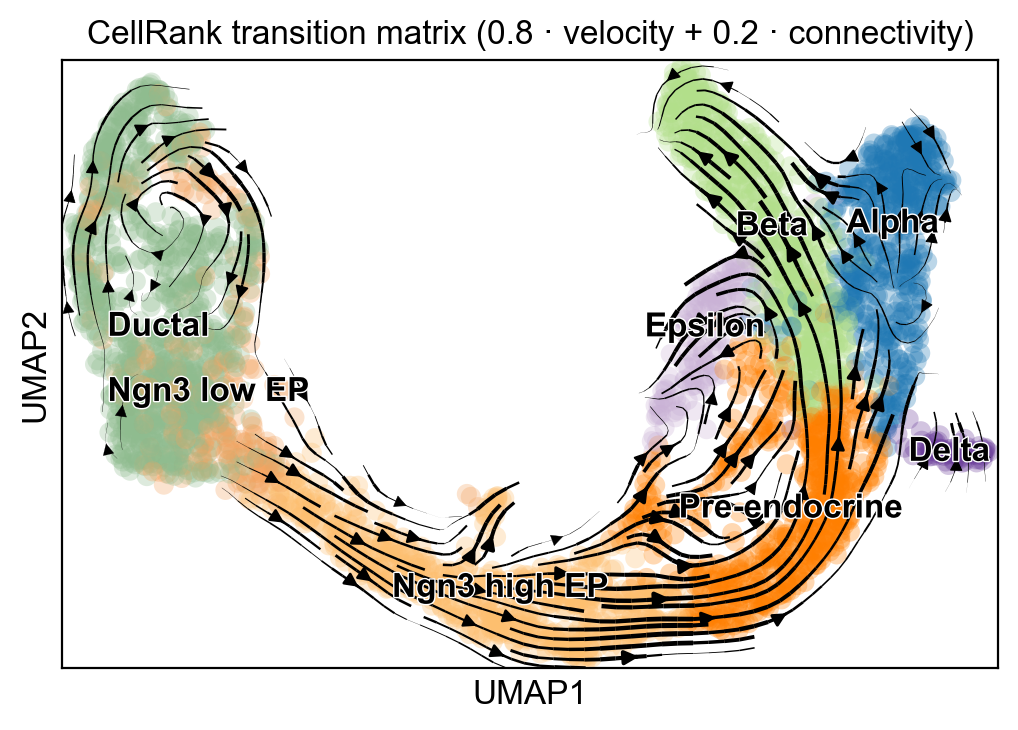

In [4]:
combined_kernel.plot_projection(
    basis="umap",
    color="clusters",
    title="CellRank transition matrix (0.8 · velocity + 0.2 · connectivity)",
    save="03_kernel_transition_projection.png",
)

## 2. Find terminal states with GPCCA

**GPCCA** (Generalized Perron Cluster Cluster Analysis) is the algorithm CellRank uses to analyze the Markov chain. Instead of looking at every individual cell, it looks for **macrostates**: groups of cells that the random walk tends to stay within for a long time before moving on ("metastable" regions of the differentiation landscape). Some macrostates are transient (a progenitor population the walk quickly passes through); others are **terminal** — once the walk enters, it essentially never leaves. Biologically, terminal macrostates correspond to fully differentiated, stable cell identities.

The first step is a **Schur decomposition** of the transition matrix — a numerically stable way to compute the leading eigenvalues, which tell us how many macrostates are worth resolving (a big "gap" between eigenvalue N and N+1 suggests N macrostates capture the stable structure well).

Computing Schur decomposition


When computing macrostates, choose a number of states NOT in `[np.int64(6), np.int64(8), np.int64(15), np.int64(18), np.int64(20)]`


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:50)


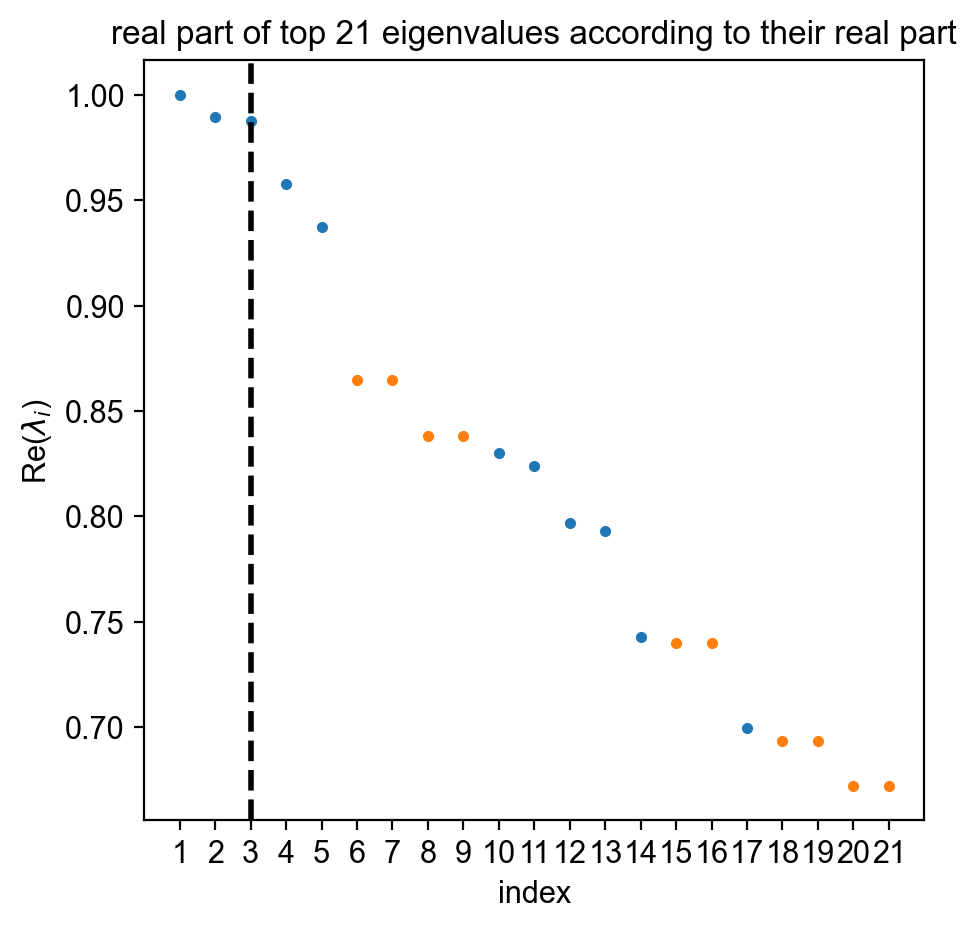

In [5]:
g = cr.estimators.GPCCA(combined_kernel)
g.compute_schur(n_components=20)
g.plot_spectrum(real_only=True, save="04_schur_eigenvalue_spectrum.png")

We need enough macrostates to let *every* mature cell type — including the numerically smaller ones — form its own metastable group. Empirically, resolving only 11 macrostates (the number used in the official tutorial's precomputed example) merges Beta cells into neighboring progenitor states here; **13 macrostates** is the smallest number that gives Alpha, Beta, Delta and Epsilon each their own state. The extra resolution mostly goes into splitting the large, heterogeneous Ductal progenitor population into several sub-states — GPCCA will label each macrostate after the dominant `clusters` identity of its cells.

Computing `13` macrostates


Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:16)


  smp = ax.scatter(
  ax.scatter(
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ..\figures/scvelo_05_macrostates_all.png


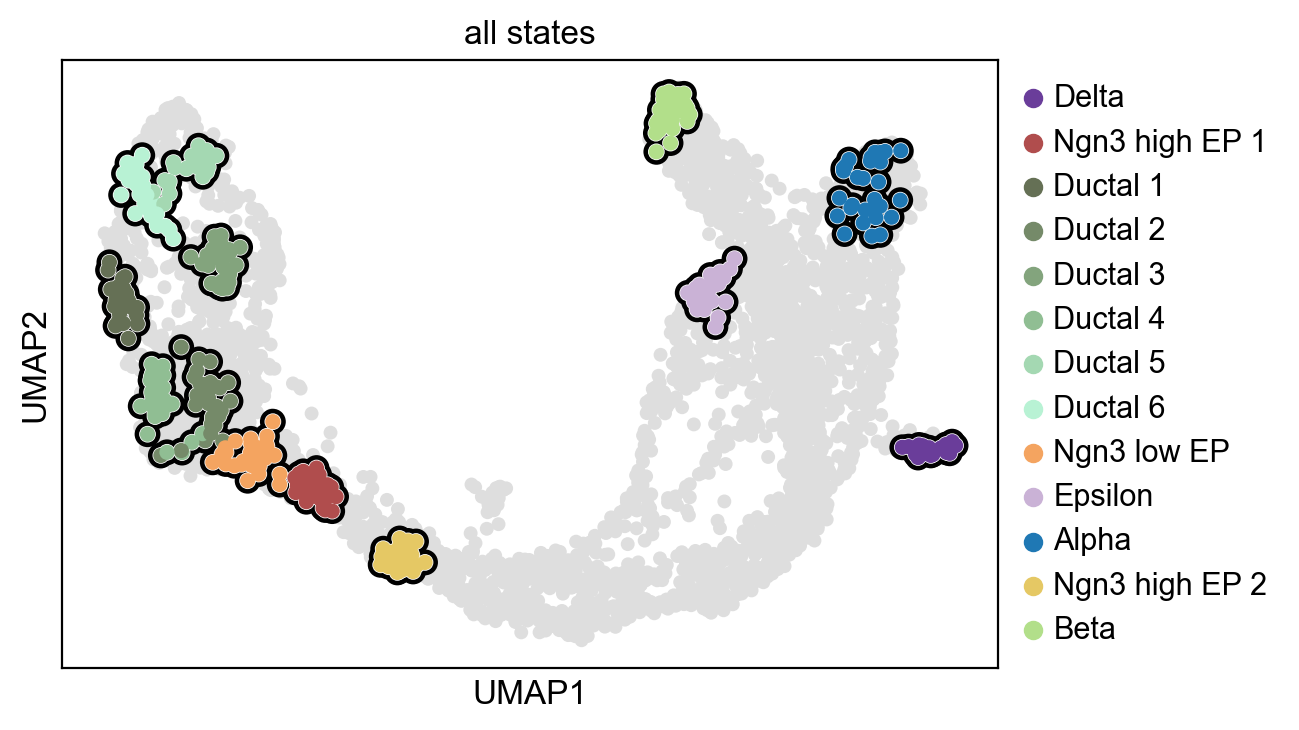

In [6]:
g.compute_macrostates(n_states=13, cluster_key="clusters")
g.plot_macrostates(which="all", legend_loc="right", s=100, save="05_macrostates_all.png")

### Automatically identify which macrostates are terminal

`predict_terminal_states()` looks at which macrostates have (almost) no outgoing probability to any other macrostate — i.e. which ones the random walk gets absorbed into. We then plot only those.

Adding `adata.obs['term_states_fwd']`
       `adata.obs['term_states_fwd_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`


  smp = ax.scatter(
  ax.scatter(
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ..\figures/scvelo_06_macrostates_terminal.png


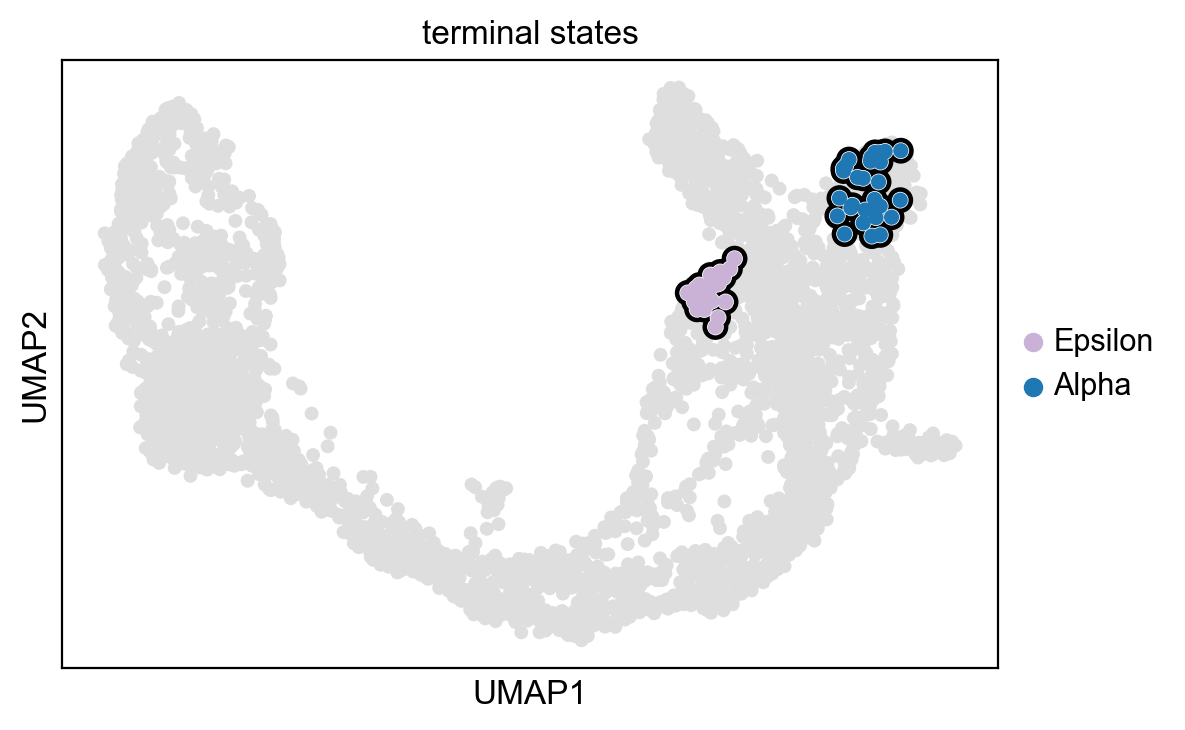

Predicted terminal states: [np.str_('Epsilon'), np.str_('Alpha')]


In [7]:
g.predict_terminal_states()
g.plot_macrostates(which="terminal", legend_loc="right", s=100, save="06_macrostates_terminal.png")
print("Predicted terminal states:", list(g.terminal_states.cat.categories))

Biologically, we expect the terminal states to be the four mature hormone-producing cell types: **Alpha** (glucagon), **Beta** (insulin), **Delta** (somatostatin) and **Epsilon** (ghrelin) cells — these are the endpoints of pancreatic endocrine differentiation and should have no further transitions out of them. If the automatic call above is noisy (e.g. splits one hormone type into two states, or includes a non-terminal state), the official tutorial's semi-automatic fix is to set the terminal states explicitly from the macrostates we already computed.

Macrostates matching the expected hormone-producing fates: ['Delta', 'Epsilon', 'Alpha', 'Beta']
Adding `adata.obs['term_states_fwd']`
       `adata.obs['term_states_fwd_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`


  smp = ax.scatter(
  ax.scatter(
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ..\figures/scvelo_06_macrostates_terminal.png


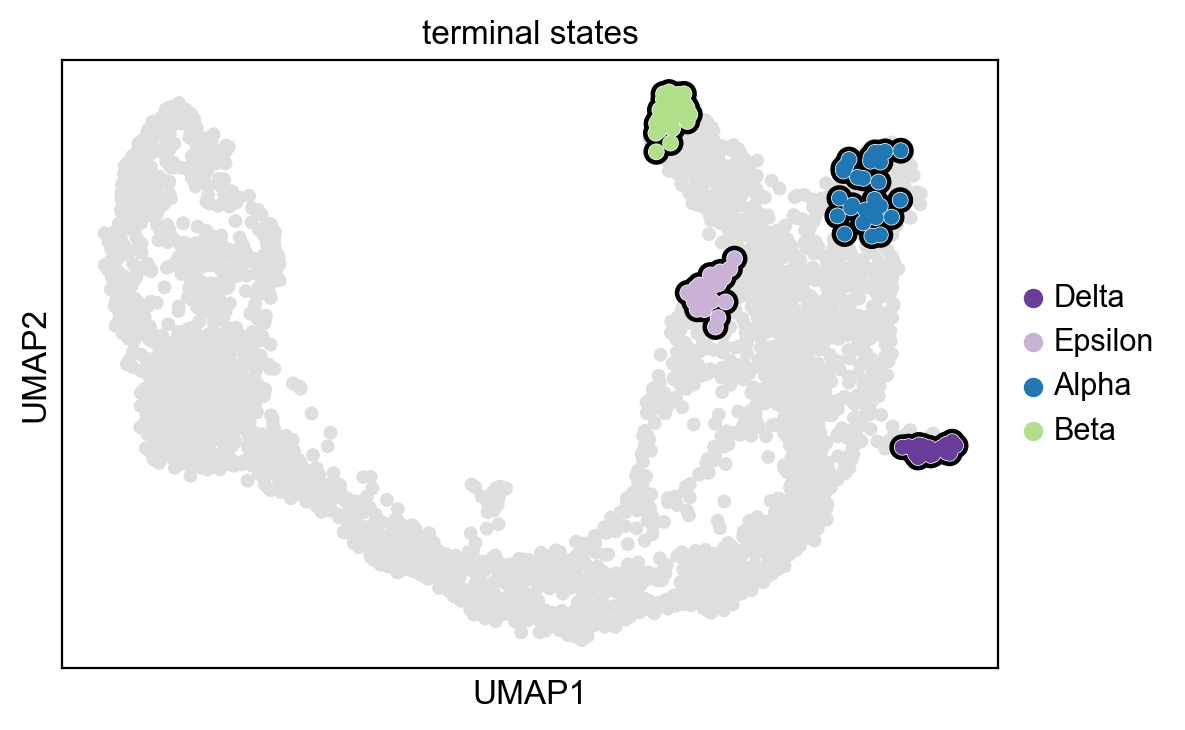

Final terminal states: [np.str_('Delta'), np.str_('Epsilon'), np.str_('Alpha'), np.str_('Beta')]


In [8]:
expected_fates = ["Alpha", "Beta", "Delta", "Epsilon"]
macrostate_names = list(g.macrostates.cat.categories)
matching_states = [s for s in macrostate_names if any(s.startswith(f) for f in expected_fates)]
print("Macrostates matching the expected hormone-producing fates:", matching_states)

if set(matching_states) != set(g.terminal_states.cat.categories):
    g.set_terminal_states(states=matching_states)
    g.plot_macrostates(which="terminal", legend_loc="right", s=100, save="06_macrostates_terminal.png")

print("Final terminal states:", list(g.terminal_states.cat.categories))

### Identify the initial state

Just as GPCCA can find **terminal** (absorbing) macrostates — the ones the random walk gets stuck in — it can also find **initial** states: macrostates that the coarse-grained dynamics start from and quickly move away from. Biologically, we expect the initial state to be an early, multipotent **Ductal** progenitor population, since in this dataset ductal cells are the source from which the Ngn3+ endocrine progenitors (and eventually all four hormone-producing types) arise.

Ductal-derived macrostates: ['Ductal_1', 'Ductal_2', 'Ductal_3', 'Ductal_4', 'Ductal_5', 'Ductal_6']
Adding `adata.obs['init_states_fwd']`
       `adata.obs['init_states_fwd_probs']`
       `.initial_states`
       `.initial_states_probabilities`
       `.initial_states_memberships
    Finish`


  smp = ax.scatter(
  ax.scatter(
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ..\figures/scvelo_06b_macrostates_initial.png


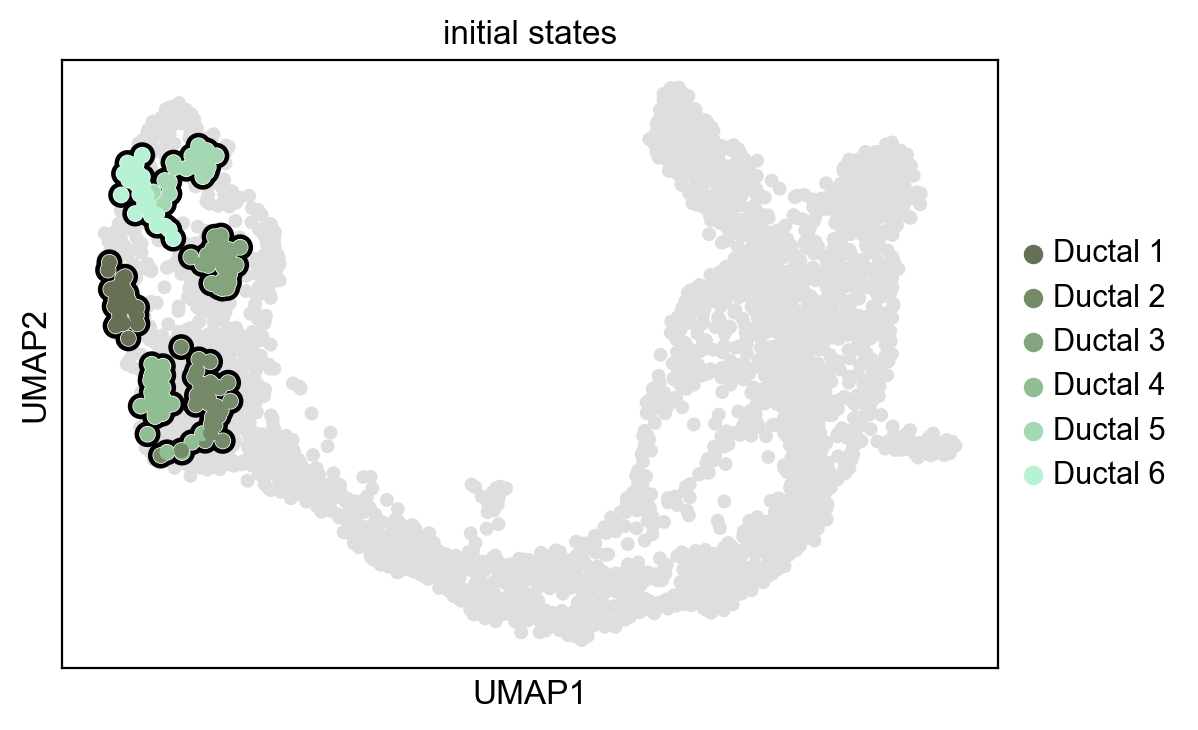

Initial state: [np.str_('Ductal_1'), np.str_('Ductal_2'), np.str_('Ductal_3'), np.str_('Ductal_4'), np.str_('Ductal_5'), np.str_('Ductal_6')]


In [9]:
initial_candidates = [s for s in macrostate_names if s.startswith("Ductal")]
print("Ductal-derived macrostates:", initial_candidates)

# `predict_initial_states()` picks macrostates by lowest coarse stationary probability, which
# can accidentally select a small/rare terminal macrostate (e.g. Epsilon) instead of the
# progenitor pool. Since we already know the biological root (Ductal), set it explicitly --
# the same semi-automatic approach used above for the terminal states.
g.set_initial_states(states=initial_candidates)
g.plot_macrostates(which="initial", legend_loc="right", s=100, save="06b_macrostates_initial.png")
print("Initial state:", list(g.initial_states.cat.categories))

### Do the terminal states match the four known endocrine types?

We expect exactly four terminal states — **Alpha, Beta, Delta, Epsilon** — each one dominated by cells that were already annotated (independently of CellRank, back when the dataset was clustered) as that hormone type, with none of the four missing and no two of them collapsed into a single macrostate. Rather than just trusting the auto-generated macrostate names, we check this directly: for every terminal macrostate, what fraction of its assigned cells carry each `clusters` label?

In [10]:
import pandas as pd

expected_fates = ["Alpha", "Beta", "Delta", "Epsilon"]
terminal_cats = list(g.terminal_states.cat.categories)
print("Terminal states found:", terminal_cats)

missing = [f for f in expected_fates if not any(t.startswith(f) for t in terminal_cats)]
print("Expected hormone types with NO matching terminal state:", missing if missing else "none -- all four found")

print("\nMapping from expected fate -> terminal state name(s) (more than one name = split/duplicated; zero = missing):")
for fate in expected_fates:
    matches = [t for t in terminal_cats if t.startswith(fate)]
    print(f"  {fate}: {matches if matches else 'MISSING'}")

mask = g.terminal_states.notna()
composition = (
    pd.crosstab(g.terminal_states[mask], adata.obs.loc[mask, "clusters"])
    .pipe(lambda df: df.div(df.sum(axis=1), axis=0) * 100)
    .round(1)
)
print("\nCluster composition (%) of cells assigned to each terminal macrostate:")
composition

Terminal states found: [np.str_('Delta'), np.str_('Epsilon'), np.str_('Alpha'), np.str_('Beta')]
Expected hormone types with NO matching terminal state: none -- all four found

Mapping from expected fate -> terminal state name(s) (more than one name = split/duplicated; zero = missing):
  Alpha: [np.str_('Alpha')]
  Beta: [np.str_('Beta')]
  Delta: [np.str_('Delta')]
  Epsilon: [np.str_('Epsilon')]

Cluster composition (%) of cells assigned to each terminal macrostate:


clusters,Beta,Alpha,Delta,Epsilon
row_0,,,,
Delta,0.0,0.0,100.0,0.0
Epsilon,0.0,0.0,0.0,100.0
Alpha,0.0,100.0,0.0,0.0
Beta,100.0,0.0,0.0,0.0


## 3. Compute fate probabilities

Now that the terminal states (absorbing states) are fixed, CellRank computes, for **every cell** in the dataset, its **absorption probability** towards each terminal state — the probability that a random walk starting at that cell, and following the Markov chain we built, eventually ends up there. A progenitor cell early in the trajectory will typically have its probability mass spread across several fates; a cell that is already close to (or part of) a terminal state will have close to 100% probability assigned to that one fate. This is CellRank's way of quantifying "lineage priming" — how committed each cell already is to a particular fate, before it actually looks like that fate.

Computing fate probabilities


Defaulting to `'gmres'` solver.


  0%|          | 0/4 [00:00<?, ?/s]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:00:00)


saving figure to file ..\figures/scvelo_07_fate_probabilities_per_lineage.png


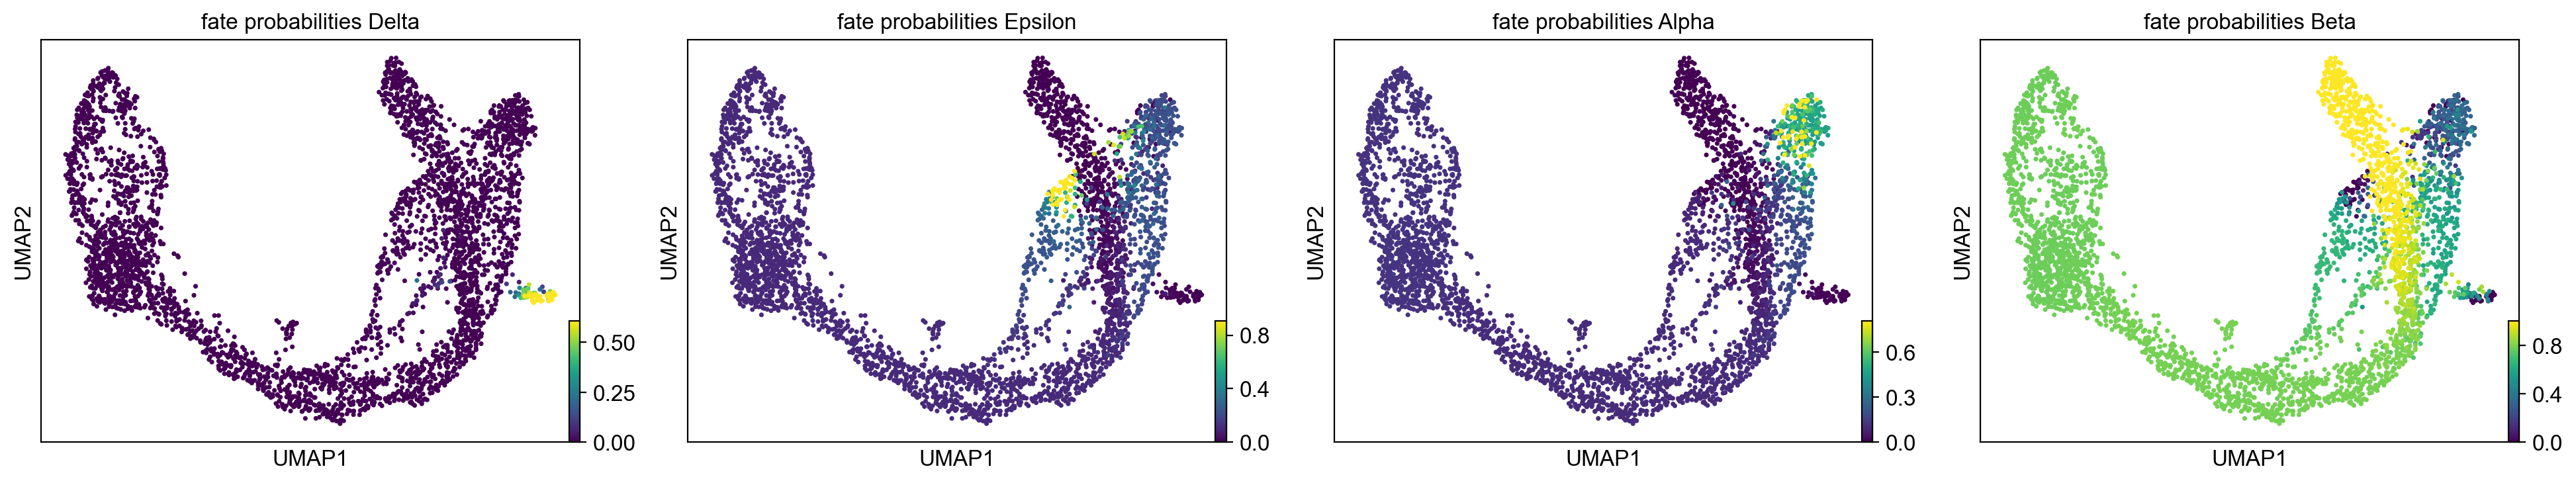

In [11]:
g.compute_fate_probabilities(solver="direct")
g.plot_fate_probabilities(same_plot=False, save="07_fate_probabilities_per_lineage.png")

A single combined plot (one color per fate, blended by each cell's probabilities) makes it easy to see the "decision boundaries" where cells commit to one fate over another.

  smp = ax.scatter(
  smp = ax.scatter(


saving figure to file ..\figures/scvelo_08_fate_probabilities_combined.png


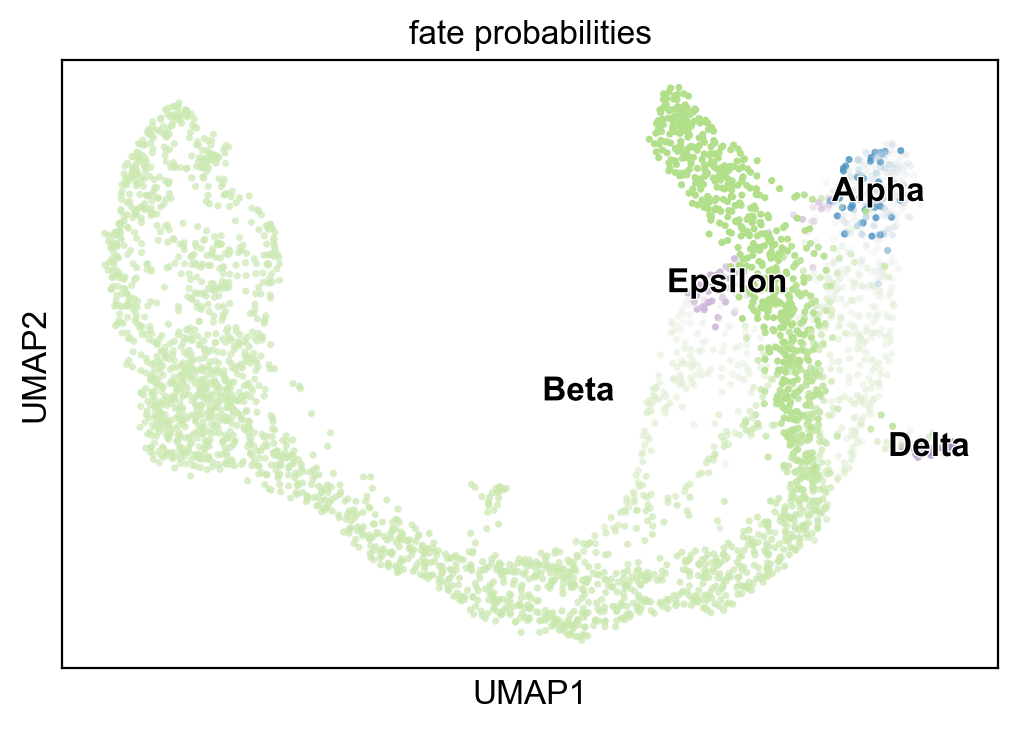

In [12]:
g.plot_fate_probabilities(same_plot=True, save="08_fate_probabilities_combined.png")

### Is the Beta skew real?

The combined plot above hints that a lot of cells lean towards a Beta fate. Two follow-up questions matter before trusting the driver genes computed from these probabilities: (1) is that lean confined to progenitor cells, where the fate decision is still being made, or does it also show up in cells that are already mature Alpha/Delta/Epsilon cells? and (2) is it just a difference of *degree* (same most-likely fate, smaller margin), or a difference of *ranking* (the model predicts the wrong fate as most likely)? We check both with two tables: (1) mean fate probability per lineage for every `clusters` label, and (2) within each hormone-producing cluster, the 30 highest-confidence terminal-state "anchor" cells versus the rest of that cluster.

In [13]:
import numpy as np

lineage_names = list(g.terminal_states.cat.categories)

fate_probs = pd.DataFrame(
    np.asarray(adata.obsm["lineages_fwd"]), columns=lineage_names, index=adata.obs_names
)
fate_probs["clusters"] = adata.obs["clusters"].values
fate_probs["term_state"] = adata.obs["term_states_fwd"].values

cluster_order = ["Ductal", "Ngn3 low EP", "Ngn3 high EP", "Pre-endocrine", "Beta", "Alpha", "Delta", "Epsilon"]

table1 = fate_probs.groupby("clusters", observed=True)[lineage_names].mean().reindex(cluster_order)
table1.insert(0, "n_cells", fate_probs.groupby("clusters", observed=True).size().reindex(cluster_order))

print("Table 1: mean fate probability per lineage, by cluster")
table1.round(3)

Table 1: mean fate probability per lineage, by cluster


,n_cells,Delta,Epsilon,Alpha,Beta
clusters,,,,,
Ductal,916,0.001,0.104,0.118,0.777
Ngn3 low EP,262,0.001,0.104,0.114,0.781
Ngn3 high EP,642,0.001,0.108,0.100,0.791
Pre-endocrine,592,0.005,0.115,0.095,0.786
Beta,591,0.001,0.014,0.014,0.971
Alpha,481,0.001,0.219,0.371,0.409
Delta,70,0.635,0.010,0.007,0.348
Epsilon,142,0.005,0.490,0.070,0.435


In [14]:
rows = []
for c in ["Alpha", "Beta", "Delta", "Epsilon"]:
    in_term = fate_probs[(fate_probs["clusters"] == c) & (fate_probs["term_state"] == c)]
    out_term = fate_probs[(fate_probs["clusters"] == c) & (fate_probs["term_state"].isna())]

    row_in = {"cluster": c, "group": "inside terminal state (anchor cells)", "n": len(in_term)}
    row_in.update(in_term[lineage_names].mean().round(3).to_dict())
    rows.append(row_in)

    row_out = {"cluster": c, "group": "outside terminal state (rest of cluster)", "n": len(out_term)}
    row_out.update(out_term[lineage_names].mean().round(3).to_dict())
    rows.append(row_out)

table2 = pd.DataFrame(rows)
print("Table 2: mean fate probability per lineage, inside vs. outside the terminal-state anchor cells")
table2

Table 2: mean fate probability per lineage, inside vs. outside the terminal-state anchor cells


,cluster,group,n,Delta,Epsilon,Alpha,Beta
0,Alpha,inside terminal state (anchor cells),30,0.000,0.000,1.000,0.000
1,Alpha,outside terminal state (rest of cluster),451,0.001,0.233,0.329,0.436
2,Beta,inside terminal state (anchor cells),30,0.000,0.000,0.000,1.000
3,Beta,outside terminal state (rest of cluster),561,0.001,0.015,0.015,0.969
4,Delta,inside terminal state (anchor cells),30,1.000,0.000,0.000,0.000
5,Delta,outside terminal state (rest of cluster),40,0.361,0.017,0.012,0.610
6,Epsilon,inside terminal state (anchor cells),30,0.000,1.000,0.000,0.000
7,Epsilon,outside terminal state (rest of cluster),112,0.007,0.353,0.089,0.551


**What this means.** The "inside terminal state" rows aren't informative on their own — those 30 anchor cells are, by construction, forced to ~100% probability of their own fate (that's the absorbing boundary condition CellRank uses to *define* the terminal states in the first place). The real signal is in the "outside terminal state" rows, which cover the other 85-95% of each hormone cluster.

For the **progenitor clusters** (Ductal, Ngn3 low/high EP, Pre-endocrine), a strong lean towards Beta is plausible, not obviously wrong: Beta is the largest terminal population (591 of 3696 cells), so progenitors having their highest raw probability point towards Beta is consistent with Beta genuinely being the dominant fate at this stage — the ranking is very likely correct, even if the exact margin over Alpha/Epsilon/Delta shouldn't be taken too literally.

For the **mature Alpha, Delta and Epsilon clusters**, it's a different and more serious problem: outside the anchor cells, the fate *ranking itself flips*. Alpha cells are predicted 32.9% Alpha vs. 43.6% Beta; Delta cells 36.1% Delta vs. 61.0% Beta; Epsilon cells 35.3% Epsilon vs. 55.1% Beta. In each case Beta is ranked as the single *most likely* fate for cells that are already, biologically, Alpha/Delta/Epsilon cells — not just a smaller margin on the correct answer, but the wrong answer coming out on top. That's a genuine error in the model's output for cells that should be the most clear-cut, and it's what the next section tries to diagnose.

## 4. Diagnosing the Beta skew

Rather than retuning kernel parameters broadly, we check two concrete hypotheses and one robustness question:

1. Could weak RNA velocity signal in mature cells explain the random walk drifting back towards the Beta basin instead of staying absorbed in its own terminal state?
2. Is the terminal-state definition (only 30 anchor cells per lineage) too narrow — does using a larger anchor set change the picture, especially for progenitors?
3. Since the skew is worst for already-differentiated cells, are the driver genes found in Section 5 partly reflecting that downstream noise rather than the actual fate decision? (We address this by restricting the driver computation to progenitor cells, later in Section 5.)

### Velocity confidence and length by cluster

scVelo's `velocity_confidence` measures how well a cell's velocity vector agrees with its neighbors' (high = coherent local flow; low = noisy or conflicting signal). `velocity_length` is the magnitude of the velocity vector (near zero = the cell looks transcriptionally "static," so RNA velocity has little directional information to offer). If mature hormone-producing cells have low confidence and/or low length, their `VelocityKernel` transition probabilities become close to uninformative — in which case the direction of the random walk at those cells is effectively dictated by the undirected `ConnectivityKernel` term (plain transcriptomic similarity), which has no reason to respect the one-way logic of differentiation and could easily route a walk from a "quiet" Alpha/Delta/Epsilon cell back towards nearby, Beta-adjacent neighbors.

In [15]:
scv.tl.velocity_confidence(adata)

conf_table = (
    adata.obs.groupby("clusters", observed=True)[["velocity_length", "velocity_confidence"]]
    .mean()
    .reindex(cluster_order)
    .round(3)
)
conf_table

--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)


--> added 'velocity_confidence_transition' (adata.obs)


,velocity_length,velocity_confidence
clusters,,
Ductal,8.044,0.808
Ngn3 low EP,7.643,0.796
Ngn3 high EP,8.463,0.871
Pre-endocrine,9.407,0.908
Beta,12.542,0.911
Alpha,7.750,0.769
Delta,10.665,0.935
Epsilon,9.016,0.818


**What this means.** The data does *not* support the low-confidence hypothesis for most of the affected clusters. Beta and Delta — the two clusters where the Beta skew is strongest outside the anchor cells — actually have the **highest** velocity confidence in the whole dataset (0.911 and 0.935, versus 0.77-0.91 for the progenitor clusters), and Delta also has a long, well-defined velocity vector (length 10.7, second only to Beta's 12.5). Epsilon's confidence (0.818) and length (9.0) are unremarkable — right in the middle of the pack, not noticeably lower than the progenitor clusters. Only **Alpha** stands out as genuinely low: its velocity confidence (0.769) and length (7.75) are the lowest of any cluster, which could plausibly make its random walk easier to pull off course by the undirected connectivity term.

So this hypothesis explains, at best, part of the Alpha skew — it does **not** explain Delta or Epsilon, both of which have strong, well-defined velocity signal and are still predicted to drift towards Beta more often than not. The cause is more likely structural: something about the transition matrix's basin geometry (plausibly Beta's large size and central position in the kNN graph) pulls disproportionate probability mass towards it regardless of how clean the local velocity signal is.

### Sensitivity check: does a larger terminal-state anchor set change the picture?

The terminal states above are each defined by their 30 highest-membership cells (`n_cells=30`, CellRank's default). If that anchor set is too narrow, enlarging it could shift which cells anchor the absorbing boundary and, with it, the fate probabilities computed for everyone else.

**A caveat about `n_cells` that matters here:** GPCCA's `n_cells` parameter selects the top-N cells *by raw macrostate membership score alone* — it does not require that macrostate to also match the cell's own `clusters` label. If a macrostate's pool of genuinely high-membership cells is smaller than `n_cells`, the selection quietly reaches into lower-membership cells from *other* clusters, including progenitors. That would make any resulting change in progenitor fate probabilities partly circular (a progenitor cell relabeled as a terminal-state anchor is, by construction, forced to ~100% probability of that fate). So before trusting a comparison at `n_cells=100`, we first check where those anchor cells actually come from.

In [16]:
# First, confirm the default n_cells=30 -- used for every other result in this notebook,
# not just this sensitivity check -- doesn't have the same problem.
default_mask = g.terminal_states.notna()
default_composition = pd.crosstab(g.terminal_states[default_mask], adata.obs.loc[default_mask, "clusters"])
print("Cluster of origin for the default n_cells=30 anchor cells (used throughout this notebook):")
default_composition

Cluster of origin for the default n_cells=30 anchor cells (used throughout this notebook):


clusters,Beta,Alpha,Delta,Epsilon
row_0,,,,
Delta,0,0,30,0
Epsilon,0,0,0,30
Alpha,0,30,0,0
Beta,30,0,0,0


Good — at `n_cells=30`, all four terminal states are 100% pure (30/30 cells from their own `clusters` label, matching the crosstab in "Do the terminal states match the four known endocrine types?" earlier). The driver-gene results and Tables 1-2 above are unaffected by the contamination found below, which only appears once the anchor-set size is pushed past the number of real cells available.

In [17]:
# Save the original (n_cells=30) fate probabilities for comparison -- `fate_probs` already
# holds them from the "Is the Beta skew real?" section above.
original_fate_probs = fate_probs[["clusters"] + lineage_names].copy()

# Naively asking for n_cells=100 anchors per macrostate, and checking where those cells
# actually come from (allow_overlap is needed here purely because this wider, less selective
# pool happens to reach cells already claimed by the n_cells=30 initial states -- it is not
# needed for, and does not affect, the cluster-restricted version below).
g.set_terminal_states(states=matching_states, n_cells=100, allow_overlap=True)
naive_mask = g.terminal_states.notna()
naive_composition = pd.crosstab(g.terminal_states[naive_mask], adata.obs.loc[naive_mask, "clusters"])
print("Cluster of origin for the naive n_cells=100 anchor cells:")
naive_composition

Adding `adata.obs['term_states_fwd']`
       `adata.obs['term_states_fwd_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`


Cluster of origin for the naive n_cells=100 anchor cells:


clusters,Ductal,Ngn3 low EP,Pre-endocrine,Beta,Alpha,Delta,Epsilon
row_0,,,,,,,
Delta,33,10,0,0,0,57,0
Epsilon,0,0,1,0,5,0,94
Alpha,0,0,0,0,100,0,0
Beta,0,0,0,100,0,0,0


**The naive selection is contaminated.** Alpha and Beta anchors are 100% pure even at `n_cells=100` (both clusters have far more than 100 cells). But Delta's 100 "anchors" include only 57 real Delta cells — the other 43 are 33 Ductal and 10 Ngn3 low EP cells — and Epsilon's include 5 Alpha cells and 1 Pre-endocrine cell alongside 94 real Epsilon cells. Delta only has 70 cells in the entire dataset, so asking for 100 forces the selection to reach past every real Delta cell and into whichever progenitor cells happen to have the next-highest Delta membership score. This means the check is invalid as originally run: we fix it below by restricting each lineage's anchor pool to cells that already carry that lineage's own `clusters` label.

In [18]:
# For each lineage, take the top cells by macrostate membership score, restricted to cells
# that already carry that lineage's own `clusters` label. Delta only has 70 such cells in the
# whole dataset, so it gets all 70; the others have far more than 100 and are capped at 100.
memberships = g.macrostates_memberships
cluster_restricted_states = {}
for fate in expected_fates:
    mem_col = pd.Series(np.asarray(memberships[fate].X).ravel(), index=adata.obs_names)
    own_cluster_cells = adata.obs_names[adata.obs["clusters"] == fate]
    n_take = min(100, len(own_cluster_cells))
    cluster_restricted_states[fate] = (
        mem_col.loc[own_cluster_cells].sort_values(ascending=False).head(n_take).index.tolist()
    )
    print(f"{fate}: {len(own_cluster_cells)} cells available in its own cluster, took {n_take}")

g.set_terminal_states(states=cluster_restricted_states, cluster_key="clusters")
restricted_mask = g.terminal_states.notna()
restricted_composition = pd.crosstab(g.terminal_states[restricted_mask], adata.obs.loc[restricted_mask, "clusters"])
print("\nCluster-restricted anchor composition (should be fully pure):")
print(restricted_composition)

g.compute_fate_probabilities(solver="direct")
large_fate_probs = pd.DataFrame(
    np.asarray(adata.obsm["lineages_fwd"]),
    columns=list(g.terminal_states.cat.categories),
    index=adata.obs_names,
)
large_fate_probs["clusters"] = adata.obs["clusters"].values

progenitor_clusters = ["Ductal", "Ngn3 low EP", "Ngn3 high EP", "Pre-endocrine"]
comparison = pd.concat(
    {
        "n_cells=30 (original)": original_fate_probs.groupby("clusters", observed=True)[lineage_names]
        .mean()
        .loc[progenitor_clusters],
        "cluster-restricted (up to 100)": large_fate_probs.groupby("clusters", observed=True)[lineage_names]
        .mean()
        .loc[progenitor_clusters],
    },
    axis=1,
)

# Restore the canonical n_cells=30 terminal states and fate probabilities for the rest of the notebook.
g.set_terminal_states(states=matching_states, n_cells=30)
g.compute_fate_probabilities(solver="direct")
print("\nRestored original terminal states (n_cells=30) and fate probabilities.")

comparison.round(4)

Alpha: 481 cells available in its own cluster, took 100
Beta: 591 cells available in its own cluster, took 100
Delta: 70 cells available in its own cluster, took 70
Epsilon: 142 cells available in its own cluster, took 100
Adding `adata.obs['term_states_fwd']`
       `adata.obs['term_states_fwd_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`



Cluster-restricted anchor composition (should be fully pure):
clusters  Beta  Alpha  Delta  Epsilon
row_0                                
Alpha        0    100      0        0
Beta       100      0      0        0
Delta        0      0     70        0
Epsilon      0      0      0      100
Computing fate probabilities


  0%|          | 0/4 [00:00<?, ?/s]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:00:00)


Adding `adata.obs['term_states_fwd']`
       `adata.obs['term_states_fwd_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`


Computing fate probabilities


  0%|          | 0/4 [00:00<?, ?/s]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:00:00)



Restored original terminal states (n_cells=30) and fate probabilities.


n_cells=30 (original)                          \
                              Delta Epsilon   Alpha    Beta   
clusters                                                      
Ductal                       0.0012  0.1035  0.1183  0.7770   
Ngn3 low EP                  0.0013  0.1044  0.1138  0.7805   
Ngn3 high EP                 0.0015  0.1079  0.1001  0.7906   
Pre-endocrine                0.0047  0.1147  0.0949  0.7857   

              cluster-restricted (up to 100)                          
                                       Delta Epsilon   Alpha    Beta  
clusters                                                              
Ductal                                0.0078  0.1324  0.1790  0.6808  
Ngn3 low EP                           0.0082  0.1386  0.1677  0.6855  
Ngn3 high EP                          0.0099  0.1601  0.1328  0.6972  
Pre-endocrine                         0.0301  0.1908  0.1188  0.6602

**What this means.** The originally reported ~375× swing in Ductal's Delta probability was largely an artifact, not a real sensitivity result: 33 of the cells forced into the naive "Delta" terminal state were actual Ductal cells, so of course the Ductal cluster's mean Delta probability shot up afterwards — those exact cells were relabeled as Delta anchors and given ~100% Delta probability by construction. The same circularity applied, more mildly, to Epsilon's 6 contaminating cells.

With contamination removed, the picture is much calmer. Across all four progenitor clusters:
- **Beta** stays clearly dominant but drops moderately (0.78-0.79 → 0.66-0.70, roughly a 12-16% relative decrease).
- **Alpha and Epsilon** both rise moderately (to 0.12-0.19, from 0.09-0.11).
- **Delta** rises about 6-6.5× (e.g. Ductal: 0.0012 → 0.0078) — real movement, but it stays roughly two orders of magnitude below the other three fates in every progenitor cluster.
- The full **ranking** (Beta far ahead; then Alpha and Epsilon trading second place depending on progenitor stage; Delta always last) is identical under both anchor-set sizes, for every progenitor cluster.

So: once the anchor cells are actually what they claim to be, **both the ranking and the order of magnitude are robust** to this hyperparameter. The exact percentages still shouldn't be read to the third decimal place, but the earlier claim that progenitor fate probabilities could swing by orders of magnitude was a property of the invalid, contaminated check — not of the underlying model.

## 5. Find driver genes for each terminal state

A **driver gene** for a given fate is a gene whose expression across cells correlates strongly with that fate's probability. Intuitively: if a gene is consistently higher in cells that are more committed to becoming Beta cells (regardless of which cluster they're currently in), it's a candidate driver — possibly a transcription factor or signaling gene that helps push cells towards that identity. `compute_lineage_drivers()` computes this correlation (plus a p-value/q-value) for every gene, separately for every terminal state.

We first compute this the default way, over **all** cells, then — given the Beta skew diagnosed in Section 4 — recompute it restricted to the progenitor clusters where the fate decision actually happens, and use that second, more trustworthy version for step 3.

In [19]:
driver_df = g.compute_lineage_drivers()
driver_df.head()

Adding `adata.varm['terminal_lineage_drivers']`
       `.lineage_drivers`
    Finish (0:00:00)


,Delta_corr,Delta_pval,Delta_qval,Delta_ci_low,Delta_ci_high,Epsilon_corr,Epsilon_pval,Epsilon_qval,Epsilon_ci_low,Epsilon_ci_high,Alpha_corr,Alpha_pval,Alpha_qval,Alpha_ci_low,Alpha_ci_high,Beta_corr,Beta_pval,Beta_qval,Beta_ci_low,Beta_ci_high
index,,,,,,,,,,,,,,,,,,,,
Sst,0.790545,0.000000e+00,0.000000e+00,0.778137,0.802336,-0.138426,2.528034e-17,1.181445e-15,-0.169909,-0.106661,-0.133206,3.845786e-16,1.977009e-14,-0.164739,-0.101400,-0.209070,4.781493e-38,3.910501e-36,-0.239696,-0.178029
Arg1,0.402886,1.628541e-148,5.860304e-145,0.375523,0.429547,0.200366,5.297096e-35,6.572966e-33,0.169218,0.231114,-0.017688,2.823734e-01,4.914731e-01,-0.049900,0.014561,-0.299843,7.692640e-79,1.628351e-76,-0.328904,-0.270214
Hhex,0.361762,2.531454e-117,6.072958e-114,0.333410,0.389460,-0.132377,5.867146e-16,2.483874e-14,-0.163918,-0.100565,-0.101638,5.719439e-10,1.434244e-08,-0.133442,-0.069626,-0.028426,8.400486e-02,1.753157e-01,-0.060611,0.003819
Mest,0.351951,1.403121e-110,2.524566e-107,0.323380,0.379882,-0.023236,1.578571e-01,3.409420e-01,-0.055436,0.009012,-0.020435,2.142258e-01,4.114134e-01,-0.052642,0.011813,-0.140963,6.479781e-18,1.895731e-16,-0.172420,-0.109218
Ptprz1,0.346887,3.379794e-107,4.864875e-104,0.318205,0.374935,-0.091495,2.464905e-08,4.434980e-07,-0.123372,-0.059429,-0.088793,6.294454e-08,1.179718e-06,-0.120689,-0.056715,-0.053893,1.044597e-03,4.681173e-03,-0.085984,-0.021689


For each terminal state, let's list the top 10 genes ranked by correlation with that fate's probability.

In [20]:
for lineage in lineage_names:
    corr_col = f"{lineage}_corr"
    if corr_col not in driver_df.columns:
        continue
    top_genes = driver_df.sort_values(corr_col, ascending=False).head(10)[[corr_col, f"{lineage}_qval"]]
    print(f"\nTop driver genes for terminal state '{lineage}' (all cells):")
    display(top_genes)


Top driver genes for terminal state 'Delta' (all cells):


,Delta_corr,Delta_qval
index,,
Sst,0.790545,0.000000e+00
Arg1,0.402886,5.860304e-145
Hhex,0.361762,6.072958e-114
Mest,0.351951,2.524566e-107
Ptprz1,0.346887,4.864875e-104
Spock3,0.288386,1.200749e-69
Fam159b,0.284497,1.049309e-67
Kctd8,0.275222,4.158409e-63
Frzb,0.271107,3.744281e-61



Top driver genes for terminal state 'Epsilon' (all cells):


,Epsilon_corr,Epsilon_qval
index,,
Ghrl,0.613464,0.000000e+00
Irx2,0.440503,4.962302e-178
Nap1l5,0.398327,1.966900e-141
Pou6f2,0.359389,2.056464e-112
Tmem27,0.336239,3.821387e-97
Arx,0.334474,4.148976e-96
Gm11837,0.315829,5.660088e-85
Gcg,0.312909,2.525779e-83
Smarca1,0.299121,1.246966e-75



Top driver genes for terminal state 'Alpha' (all cells):


,Alpha_corr,Alpha_qval
index,,
Gcg,0.781661,0.000000e+00
Irx2,0.473298,6.919899e-211
Peg10,0.471630,2.712915e-209
Wnk3,0.449540,5.444170e-187
Etv1,0.390066,4.163977e-135
Tmsb15l,0.387988,1.432772e-133
Tmem27,0.382414,2.286738e-129
Smarca1,0.381888,5.007821e-129
Dock11,0.372716,2.940028e-122



Top driver genes for terminal state 'Beta' (all cells):


,Beta_corr,Beta_qval
index,,
Nkx6-1,0.410198,1.659448e-151
Pdx1,0.380819,2.143700e-128
Nnat,0.361160,3.205581e-114
Ptma,0.357972,4.145864e-112
Ins2,0.356406,4.706886e-111
Gng12,0.350227,6.932222e-107
Sytl4,0.333287,5.776616e-96
Npepl1,0.326445,9.041174e-92
Ins1,0.292718,1.056897e-72


### Restricting drivers to the progenitor clusters where the fate decision happens

Given the Beta skew diagnosed above, the all-cell correlations are partly driven by mature Alpha/Delta/Epsilon cells whose fate probabilities we now know are often ranked wrong. The actual lineage decision is made earlier — while cells are still `Ngn3 high EP` or `Pre-endocrine` progenitors, before they commit to a hormone identity. `compute_lineage_drivers()` exposes exactly this restriction through its `cluster_key` and `clusters` arguments: we recompute the correlations using only those two progenitor clusters, so a gene only counts as a driver if its expression *in still-undecided progenitors* already predicts which fate they're leaning towards — rather than just being a marker that happens to be highly expressed once a cell has clearly become that type.

In [21]:
progenitor_clusters_for_drivers = ["Ngn3 high EP", "Pre-endocrine"]
driver_df_progenitors = g.compute_lineage_drivers(cluster_key="clusters", clusters=progenitor_clusters_for_drivers)

for lineage in lineage_names:
    corr_col = f"{lineage}_corr"
    if corr_col not in driver_df_progenitors.columns:
        continue
    top_genes = driver_df_progenitors.sort_values(corr_col, ascending=False).head(10)[[corr_col, f"{lineage}_qval"]]
    print(f"\nTop progenitor-restricted driver genes for terminal state '{lineage}':")
    display(top_genes)

Adding `adata.varm['terminal_lineage_drivers']`
       `.lineage_drivers`
    Finish (0:00:00)



Top progenitor-restricted driver genes for terminal state 'Delta':


,Delta_corr,Delta_qval
index,,
Hhex,0.571307,4.459746e-111
Sst,0.569764,1.388577e-110
Pyy,0.399588,1.747333e-46
Isl1,0.351962,8.044803e-35
Arg1,0.323708,7.009272e-29
Hadh,0.314696,3.581236e-27
Ghr,0.310262,2.201460e-26
Rbp4,0.292769,3.257557e-23
Diras2,0.283267,1.314229e-21



Top progenitor-restricted driver genes for terminal state 'Epsilon':


,Epsilon_corr,Epsilon_qval
index,,
Arx,0.494322,1.049546e-76
Peg10,0.458976,2.814889e-64
Irx2,0.394702,3.562492e-45
Tmem27,0.391845,1.517681e-44
Mctp2,0.348252,4.364920e-34
Slc16a10,0.344597,2.334783e-33
Nap1l5,0.338784,3.646358e-32
Gast,0.336469,9.949168e-32
Ghrl,0.319226,3.072082e-28



Top progenitor-restricted driver genes for terminal state 'Alpha':


,Alpha_corr,Alpha_qval
index,,
Arx,0.320581,7.435551e-28
Epha3,0.190428,5.113508e-09
Rpl9,0.173494,2.327958e-07
Cd63,0.167515,6.878334e-07
Alcam,0.166985,7.486021e-07
Gast,0.162334,1.925244e-06
Gria2,0.150282,1.683556e-05
Ifitm2,0.140921,8.898363e-05
Tmsb4x,0.140472,9.439649e-05



Top progenitor-restricted driver genes for terminal state 'Beta':


,Beta_corr,Beta_qval
index,,
Npepl1,0.292447,4.954777e-23
Mnx1,0.286861,4.063981e-22
Pcsk2,0.275757,2.165538e-20
Cox7a2l,0.244112,9.192667e-16
Chgb,0.241367,2.144100e-15
Nkx6-1,0.229963,6.606239e-14
Syt13,0.222730,5.452720e-13
Pdx1,0.218036,1.938821e-12
Rpl26,0.206769,3.979377e-11


**What changed.** Restricting to progenitor cells shifts every lineage's top driver list away from hormone genes and towards transcription factors:

- **Alpha:** *Gcg* (glucagon, corr 0.78, rank 1 in the all-cell list) **drops out of the top 10 entirely**. *Arx* — the transcription factor known to specify alpha-cell fate — takes rank 1, despite not appearing in the all-cell top 10 at all.
- **Epsilon:** *Ghrl* (ghrelin) falls from rank 1 (corr 0.61) to rank 9 (corr 0.32). *Arx* again rises to rank 1 (it was rank 6 in the all-cell version).
- **Delta:** *Sst* (somatostatin) falls from rank 1 to rank 2, overtaken by *Hhex*, a transcription factor with an established role in Delta-cell specification. *Isl1*, a core pancreatic-islet TF, newly enters at rank 4.
- **Beta:** *Ins1* and *Ins2* (insulin) **drop out of the top 10 entirely**. *Nkx6-1* and *Pdx1* — the two Beta-specifying TFs already flagged as biologically sensible in Section 5 — stay in the list but fall from ranks 1-2 to ranks 6 and 8. New entries include *Mnx1* (a pancreatic/motor-neuron TF) and processing/secretory genes (*Pcsk2*, *Chgb*, *Syt13*) that act downstream of fate commitment but upstream of mature hormone production.

This is the expected signature of removing the Beta-skew contamination: hormone genes are so strongly expressed once a cell *is* that type that they dominate an all-cell correlation almost by definition, regardless of whether they're informative earlier. Restricting to the two progenitor clusters where the decision is actually being made surfaces the transcription factors that plausibly drive the decision instead.

### Visualize top Beta drivers along the Beta lineage

A correlation table tells us *which* genes matter, but not *how* their expression actually changes as a cell commits to becoming Beta. To see that, we need a time axis. We use scVelo's **latent time** — a per-cell estimate (0 = least differentiated, 1 = most differentiated) of transcriptional progression, derived from the dynamical model fitted in notebook 1. For each top driver gene (from the progenitor-restricted list above, since that's now our canonical driver set) we then fit a smooth curve (a GAM — generalized additive model) of expression versus latent time, using only cells weighted by how committed they are to the Beta fate, so cells that are actually headed towards Alpha/Delta/Epsilon don't distort the trend.

In [22]:
scv.tl.latent_time(adata)
adata.obs[["latent_time"]].describe()

computing terminal states


    identified 1 region of root cells and 1 region of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior


    finished (0:00:02) --> added 
    'latent_time', shared time (adata.obs)


,latent_time
count,3696.000000
mean,0.535447
std,0.295183
min,0.000000
25%,0.181230
50%,0.648110
75%,0.778280
max,1.000000


Plotting expression trends for top progenitor-restricted Beta drivers: ['Npepl1', 'Mnx1', 'Pcsk2', 'Cox7a2l']
Computing trends using `1` core(s)


  0%|          | 0/4 [00:00<?, ?gene/s]

    Finish (0:00:00)


Plotting trends


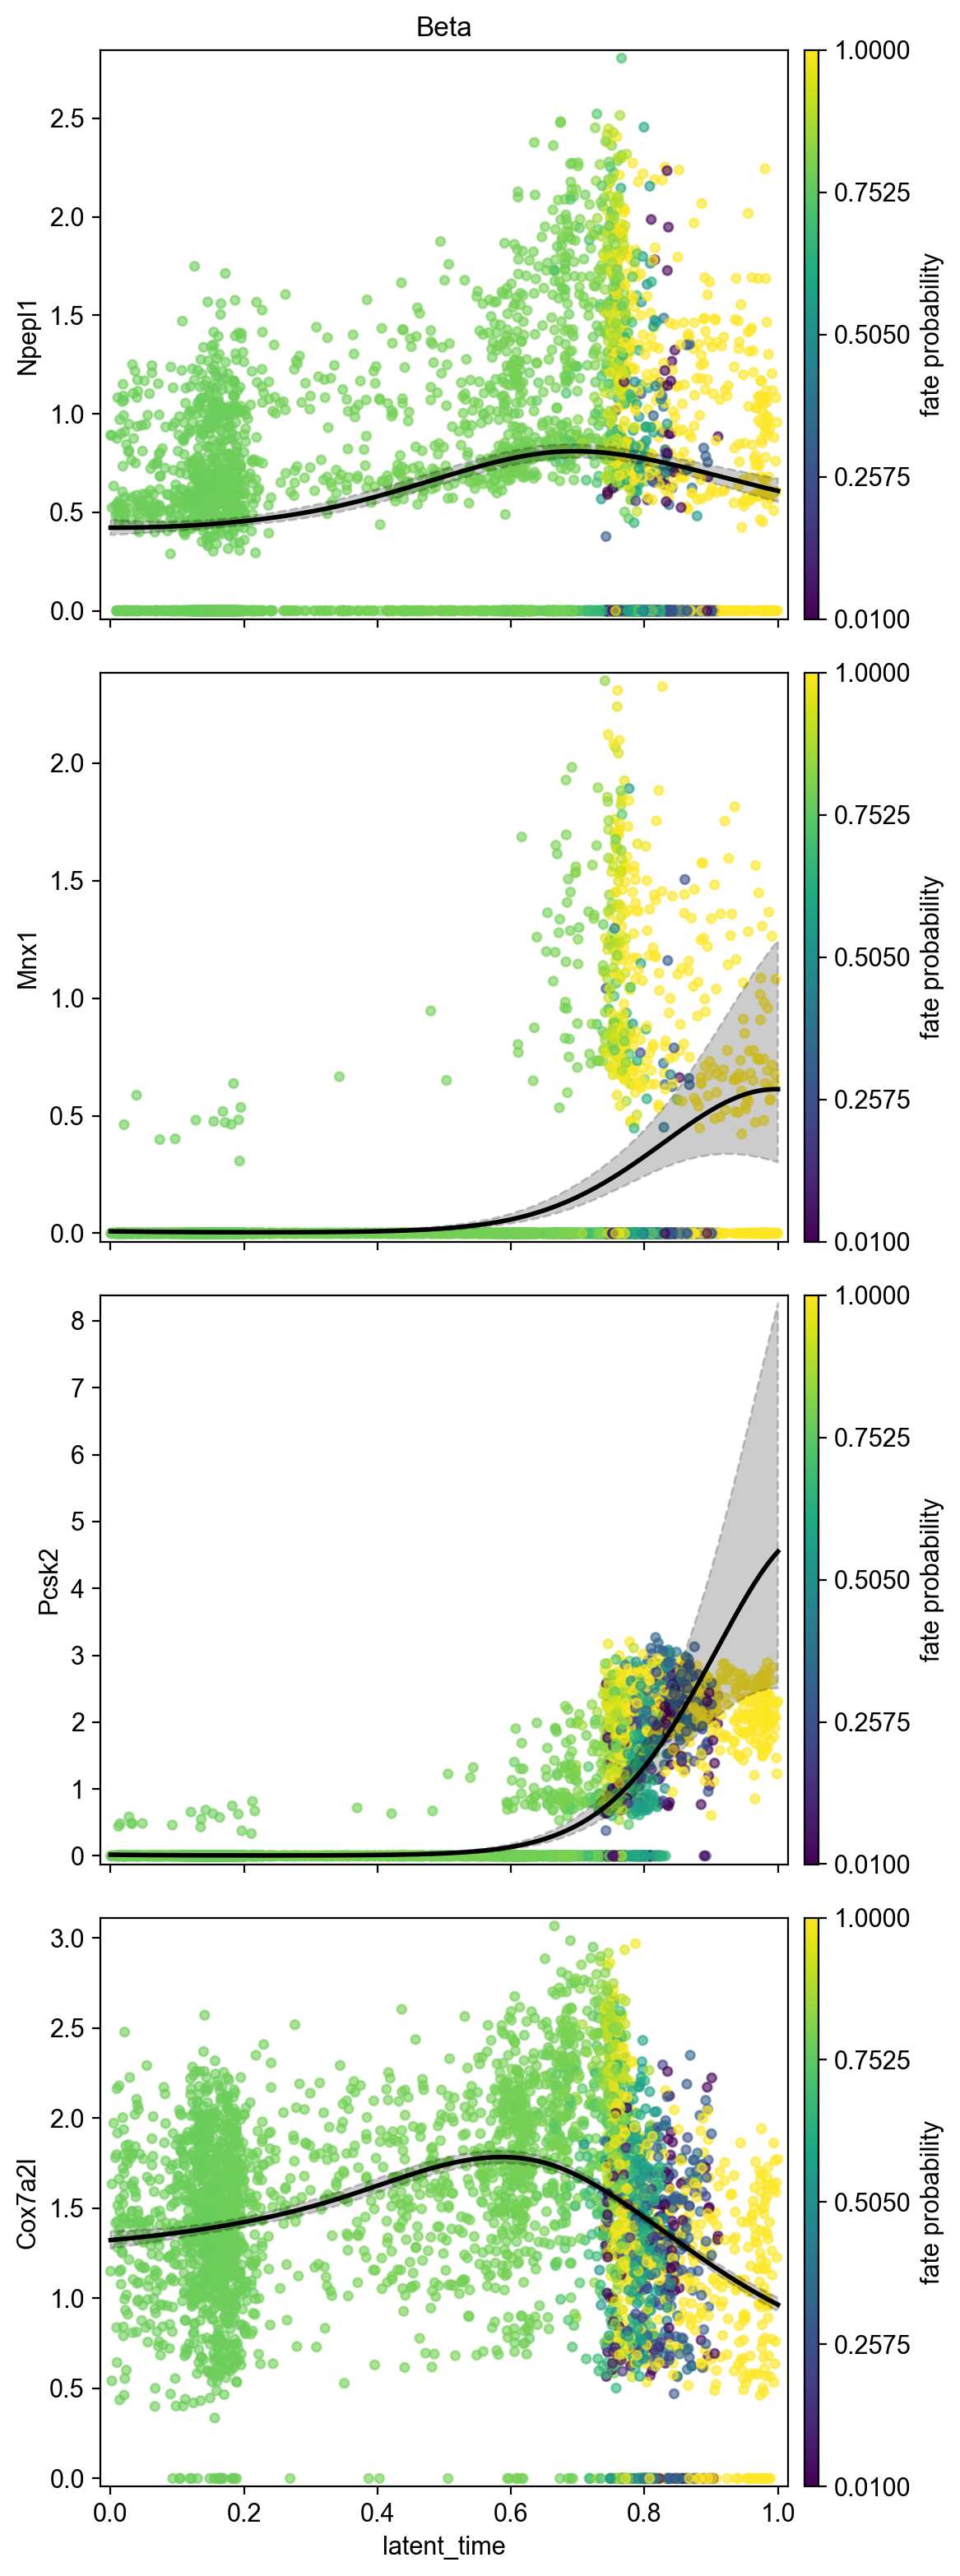

In [23]:
from cellrank.models import GAM

beta_top_genes = driver_df_progenitors.sort_values("Beta_corr", ascending=False).head(4).index.tolist()
print("Plotting expression trends for top progenitor-restricted Beta drivers:", beta_top_genes)

model = GAM(adata)
cr.pl.gene_trends(
    adata,
    model=model,
    genes=beta_top_genes,
    lineages=["Beta"],
    time_key="latent_time",
    ncols=2,
    same_plot=False,
    hide_cells=False,
    n_jobs=1,
    save="09_beta_lineage_top_drivers.png",
)

## 6. Save results for step 3

We save two things for the next notebook: (1) the full AnnData object — now carrying fate probabilities and driver-gene statistics on top of everything from notebook 1 — and (2) plain CSV tables of the top driver genes per lineage. We save **both** driver computations: the progenitor-restricted one (Section 5) becomes the canonical `lineage_drivers_all_genes.csv` / `top10_drivers_<lineage>.csv` used in step 3, since it's less contaminated by the Beta skew; the original all-cell computation is kept too, under an `_allcells` suffix, for reference.

In [24]:
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

adata.write(DATA_DIR / "pancreas_fates.h5ad")
print(f"Saved AnnData with fate probabilities and drivers to {DATA_DIR / 'pancreas_fates.h5ad'}")

# Original, all-cell driver computation -- kept for reference under an "_allcells" suffix.
driver_df.to_csv(RESULTS_DIR / "lineage_drivers_all_genes_allcells.csv")
print(f"Saved all-cell driver table to {RESULTS_DIR / 'lineage_drivers_all_genes_allcells.csv'}")

for lineage in lineage_names:
    corr_col = f"{lineage}_corr"
    if corr_col not in driver_df.columns:
        continue
    top10 = driver_df.sort_values(corr_col, ascending=False).head(10)[[corr_col, f"{lineage}_pval", f"{lineage}_qval"]]
    out_path = RESULTS_DIR / f"top10_drivers_{lineage.lower()}_allcells.csv"
    top10.to_csv(out_path)
    print(f"Saved {out_path}")

# Progenitor-restricted drivers -- the canonical set used for step 3, since they're less
# contaminated by the Beta fate-probability skew in already-differentiated cells.
driver_df_progenitors.to_csv(RESULTS_DIR / "lineage_drivers_all_genes.csv")
print(f"\nSaved progenitor-restricted driver table (canonical, for step 3) to {RESULTS_DIR / 'lineage_drivers_all_genes.csv'}")

for lineage in lineage_names:
    corr_col = f"{lineage}_corr"
    if corr_col not in driver_df_progenitors.columns:
        continue
    top10 = driver_df_progenitors.sort_values(corr_col, ascending=False).head(10)[[corr_col, f"{lineage}_pval", f"{lineage}_qval"]]
    out_path = RESULTS_DIR / f"top10_drivers_{lineage.lower()}.csv"
    top10.to_csv(out_path)
    print(f"Saved {out_path}")

Saved AnnData with fate probabilities and drivers to ..\data\pancreas_fates.h5ad


Saved all-cell driver table to ..\results\lineage_drivers_all_genes_allcells.csv
Saved ..\results\top10_drivers_delta_allcells.csv
Saved ..\results\top10_drivers_epsilon_allcells.csv
Saved ..\results\top10_drivers_alpha_allcells.csv
Saved ..\results\top10_drivers_beta_allcells.csv



Saved progenitor-restricted driver table (canonical, for step 3) to ..\results\lineage_drivers_all_genes.csv
Saved ..\results\top10_drivers_delta.csv
Saved ..\results\top10_drivers_epsilon.csv
Saved ..\results\top10_drivers_alpha.csv
Saved ..\results\top10_drivers_beta.csv


## Summary

**Pipeline.** Starting from the RNA velocity fit in `01_velocity.ipynb`, we built a `VelocityKernel` (blended 80/20 with a `ConnectivityKernel`), ran GPCCA with 13 macrostates, identified terminal and initial states, computed per-cell fate probabilities and lineage-driver genes, diagnosed a fate-probability skew, and saved everything for step 3.

**What the model found.**
- **Initial state:** six Ductal sub-macrostates (`Ductal_1`–`Ductal_6`), all correctly sitting at the root of the process.
- **Terminal states:** all four known endocrine types — Alpha, Beta, Delta, Epsilon — recovered and 100% pure against the `clusters` annotation at the default `n_cells=30` used throughout this notebook, though the fully automatic `predict_terminal_states()` call only found 2 of the 4 and had to be corrected by name.
- **Driver genes:** the top correlate for each lineage, computed over all cells, is exactly the hormone gene that defines it (*Gcg*, *Sst*, *Ghrl*, with *Nkx6-1*/*Pdx1* for Beta) — biologically sensible, but see below for why we don't use this version for step 3.
- **Latent time** increases monotonically along the expected route: Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine → the four hormone types.

**What causes the Beta skew.** Mean fate probabilities lean heavily towards Beta almost everywhere, and for the mature Alpha, Delta and Epsilon clusters this isn't just a smaller margin — outside their 30 anchor cells, Beta is ranked the *most likely* fate even for cells that are already, biologically, that other type. We ruled out one explanation and couldn't rule out another:
- **Not explained by weak velocity signal**, for the most part. Delta and Epsilon — where the skew is worst — have average-to-best-in-dataset velocity confidence and length. Only Alpha has a genuinely low-confidence, short velocity signal, so this may explain *part* of the Alpha skew but not Delta or Epsilon.
- **Likely a structural / basin-geometry effect**: Beta is the largest terminal population (591 of 3696 cells) and appears to act as a disproportionately strong sink in the transition matrix regardless of local velocity quality. We didn't chase this further with broad parameter tuning, since it was out of scope here, but it's the most plausible remaining explanation.

**Are the progenitor results robust?** The **fate ranking is robust to anchor choice**; the **magnitudes are moderately sensitive**. Our first attempt at widening the terminal-state anchor set (`n_cells=100`) was invalid: GPCCA's `n_cells` selects cells by raw macrostate membership score alone, and since Delta has only 70 cells in the whole dataset, asking for 100 anchors pulled in 33 Ductal and 10 Ngn3 low EP cells (and Epsilon pulled in a smaller 6-cell contamination). This made the originally observed ~375× swing in Ductal's Delta probability substantially circular — those exact Ductal cells had been relabeled as Delta terminal-state anchors and forced to ~100% Delta probability. After restricting each lineage's anchors to cells that already carry its own `clusters` label (all 70 for Delta, 100 for the rest), the real sensitivity is much smaller: **Beta drops by 12-16%** across progenitor clusters (0.78-0.79 → 0.66-0.70), **Epsilon rises by up to +65% in Pre-endocrine** (0.115 → 0.191; less elsewhere), Alpha rises by roughly 25-50%, and **Delta rises about 6×** (e.g. Ductal: 0.0012 → 0.0078) but stays roughly two orders of magnitude below the other three fates throughout. The full fate ranking (Beta far ahead; Alpha and Epsilon trading second place depending on progenitor stage; Delta always last) is identical under both anchor-set sizes, for every progenitor cluster. So: trust the ranking; treat the exact percentages as correct to roughly ±15 percentage points, not to the decimal place.

**Why drivers are now computed in progenitors only.** Correlating gene expression against fate probability over all cells lets the Beta-skew contamination in mature cells leak into the result, and lets hormone genes dominate simply because they're switched on once a cell has already become that type — telling us little about what drove the decision. Restricting the correlation to `Ngn3 high EP` and `Pre-endocrine` cells — where fate probabilities are still correctly *ranked* even if not precisely calibrated, and where cells haven't committed yet — produces a cleaner signal: hormone genes drop out or fall sharply in rank (*Gcg* and *Ins1*/*Ins2* disappear from the Alpha/Beta top 10 entirely; *Sst* and *Ghrl* fall to #2 and #9), while known transcription factors move up or newly appear (*Arx* becomes the #1 driver for both Alpha and Epsilon; *Hhex* and *Isl1* rise for Delta; *Mnx1* newly appears for Beta alongside *Nkx6-1*/*Pdx1*). This progenitor-restricted table is what's saved as the canonical driver set for step 3; the original all-cell version is kept alongside it under an `_allcells` suffix for reference. **Caution on Delta:** its fate probability in progenitor cells is tiny (~0.001-0.03, see above) and it has only 70 cells overall, so its driver correlations rest on very little variation — step 3 reports Delta separately, with this caveat, rather than folding it into headline agreement numbers.

All figures are saved in `../figures/`; the annotated AnnData is saved to `../data/pancreas_fates.h5ad`; both driver-gene tables are saved as CSVs in `../results/`, ready for step 3.